# Energy-constrained baselines for Φ

A companion to the coupling search (`Spin_Phi_Optimization.ipynb`; notebooks 03–05 in the repository) and to the random-state baselines (`Phi_Random_Baseline_Tests.ipynb`; notebook 06 in the repository). Equation numbers refer to the analytical note `phi_analytical_calculation.pdf`. The notebook is self-contained.

**Question.** Eigenstates of the PRX Hamiltonian have Φ about 1.5× the structureless (Haar / GOE / GUE) baseline, and the optimised Hamiltonians (min 1, min 2) bring that down to about 1.15×. How much of the remaining excess, and of the improvement, comes from **energy conservation**? A Haar-random state ignores energy completely. An eigenstate is confined to a single energy.

**Energy-constrained random states.** Take the k eigenstates of H in an energy window W and apply a Haar-random rotation within their span. Use an orthogonal rotation for a real H (GOE class) and a unitary rotation for a complex H (GUE class). The rotated states have exactly the energy support of the window, but are otherwise structureless. The baseline Φ_EC(W) is E Φ for a random orthonormal pair in span(W).

- **Section B: the middle 50% of the spectrum.** W is the whole middle 50%, the same window the project's Φ uses. This is the weakest energy constraint.
- **Section C: narrower windows inside the middle 50%.** The middle 50% is split into consecutive windows of w eigenstates, for w = 2, 4, …, k_mid. As w shrinks, the constraint tightens towards "a single energy".
- **Section F: time-reversal symmetry under energy conservation.** For a real H, mixing a window's eigenstates with real coefficients respects time reversal, while complex coefficients do not. Comparing the two measures how much preserving time reversal costs once energy is conserved. A scan of the time-reversal-breaking angle, at fixed coupling strengths, tests this directly on the optimised Hamiltonians.

**Exact formula, so no sampling is needed.** For the two rotated states u = Vc and v = Vd, write Tr(ρ_u ρ_v) = Σ c_p c̄_q d_r d̄_s Tr(ρ_pq ρ_rs), where ρ_pq = Tr_B(V_p V_q†). Here (c, d) are two columns of a Haar unitary or orthogonal k × k matrix. The Weingarten integrals for two columns then give:

| rotation | E Φ for a random orthonormal pair in span(W) |
|---|---|
| unitary (complex H) | 2(k·b − a) / (k(k² − 1)) |
| orthogonal (real H) | 2(k(b + c) − 2a) / (k(k − 1)(k + 2)) |

The quantities a, b and c are computed from the window projector Π = Σ_{p∈W} V_p V_p†:
- a = Tr[(Tr_B Π)²]
- b = Tr[(Tr_A Π)²]
- c = Σ_pq Tr(ρ_pq ρ_pq) = Tr[Π Π^{T_A}], where T_A is the partial transpose on the block.

With Π = I both expressions reduce to the Haar baseline μ·D/(D−1) (PDF eq. 39). Section A checks this, and checks the formula against direct sampling.

**How to read the results:**
- **Φ_H / Φ_EC(w) ≈ 1** means the eigenstates are as structureless as energy conservation at resolution w allows.
- **Fraction of the excess explained:** f(w) = (Φ_EC(w) − Φ_Haar) / (Φ_H − Φ_Haar).

**Output.** `[PASS]` / `[FAIL]` lines are correctness checks; a table at the end collects them. `FINDING` lines report results.

**Running.** Run all cells. `QUICK = True` runs L = 9 only and uses fewer perturbation draws (about 30 seconds). `QUICK = False` adds L = 11 (7.6 minutes on an Apple M4; most of it is the L = 11 angle scan).

In [1]:
import gc, time
from functools import reduce

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.linalg import eigh
from IPython.display import display

# ---- Run configuration ------------------------------------------------------
QUICK  = False                 # True: L = 9 only, fewer perturbation draws (~30 s). False: adds L = 11 (~8 min).
SIZES  = [(9, 3)] if QUICK else [(9, 3), (11, 4)]     # (L, l) pairs, as in the main notebook
W_REF  = 8                      # reference window (eigenstates per window) for Sections D and E
SEED   = 20261124
rng    = np.random.default_rng(SEED)
NAMES  = ['PRX', 'min1', 'min2']

# ---- Plot style (one colour per Hamiltonian, fixed) ---------------------------
COL = {'PRX': '#2a78d6', 'min1': '#eb6834', 'min2': '#1baf7a'}
C_PRX_REAL, C_PRX_CPLX = '#2a78d6', '#e87ba4'     # Section F1: PRX with real vs complex mixing
plt.rcParams.update({
    'figure.dpi': 110, 'axes.grid': True, 'grid.color': '#e4e3dd', 'grid.linewidth': 0.6,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8a897f',
    'axes.labelcolor': '#3d3d3a', 'xtick.color': '#6b6a63', 'ytick.color': '#6b6a63',
    'lines.linewidth': 2, 'legend.frameon': False, 'axes.titlesize': 10, 'axes.labelsize': 9,
})

CHECKS = []
def check(name, passed, detail=''):
    CHECKS.append((name, bool(passed), detail))
    print(f"[{'PASS' if passed else 'FAIL'}] {name}" + (f"   ({detail})" if detail else ''))

T_START = time.time()
print(f'QUICK = {QUICK}, sizes = {SIZES}, seed = {SEED}')

QUICK = False, sizes = [(9, 3), (11, 4)], seed = 20261124


## Hamiltonians and shared definitions

All three Hamiltonians use the main notebook's conventions.
- **PRX:** H = Σ ZᵢZᵢ₊₁ + g ΣXᵢ + h ΣZᵢ + 0.25 Z₀ − 0.25 Z_{L−1}, with (g, h) = (1.08, 0.30). It is real, so it belongs to the GOE class.
- **min 1 / min 2:** H = J ΣZᵢZᵢ₊₁ + ΣZᵢ + edge + Σ c_k H_k, where H_k runs over the two-spin couplings XX, YY, XY+YX, XZ+ZX and YZ+ZY. The parameter vector is x6 = [J, c_XX, c_YY, c_XY+YX, c_XZ+ZX, c_YZ+ZY]. The XY+YX and YZ+ZY terms make H complex, so these belong to the GUE class.
- **Parameter sources:** the values stored in `results/minima.json` in the repository.
  - L = 9: the canonical-frame optima.
  - L = 11: the standard-frame optima (YZ+ZY = 0).
- **Reference Φ values:** from the coupling search (the README table in the repository).
- **Window:** the middle 50% of the spectrum.
- **Blocks:** contiguous blocks of ℓ + 1 spins, as in `_phi_l3` and `_phi_l4`.
- **Rotation type:** chosen from whether H is real, which is consistent with the level statistics ⟨r⟩ printed below.

In [2]:
PARAMS = {
    9:  {'PRX':  ('gh', (1.08, 0.30)),
         'min1': ('x6', [0.082343, 0.539440, 0.759689, -0.443422, 0.358522, 0.001237]),
         'min2': ('x6', [0.0639073218, 1.3102469777746573, 0.1563727956639216,
                         -0.009625111783115314, 0.2659923597166658, -0.7049065840130392])},
    11: {'PRX':  ('gh', (1.08, 0.30)),
         'min1': ('x6', [0.0723185, 0.560674, 0.731729, -0.450085, 0.362785, 0.0]),
         'min2': ('x6', [0.0639073, 0.482552, 1.38985, -0.214289, 0.878317, 0.0])},
}
REF_PHI = {9:  {'PRX': 0.09813847, 'min1': 0.07154433, 'min2': 0.07031195},   # coupling search (README table)
           11: {'PRX': 0.04553219, 'min1': 0.03677807, 'min2': 0.03634512}}

_sx = np.array([[0, 1], [1, 0]], dtype=complex)
_sy = np.array([[0, -1j], [1j, 0]])
_sz = np.diag([1.0, -1.0]).astype(complex)


def build_ops(L):
    def op(single):
        return reduce(np.kron, [single.get(i, np.eye(2)) for i in range(L)])
    def bond(a, b):
        return sum(op({i: a, i + 1: b}) for i in range(L - 1))
    ops = {'ZZ': bond(_sz, _sz), 'X': sum(op({i: _sx}) for i in range(L)),
           'Z': sum(op({i: _sz}) for i in range(L)),
           'EDGE': 0.25 * op({0: _sz}) - 0.25 * op({L - 1: _sz})}
    ops['coup'] = [bond(_sx, _sx), bond(_sy, _sy), bond(_sx, _sy) + bond(_sy, _sx),
                   bond(_sx, _sz) + bond(_sz, _sx), bond(_sy, _sz) + bond(_sz, _sy)]
    return ops


def hamiltonian(ops, kind, p):
    if kind == 'gh':
        g, h = p
        return (ops['ZZ'] + g * ops['X'] + h * ops['Z'] + ops['EDGE']).real
    H = p[0] * ops['ZZ'] + ops['Z'] + ops['EDGE']
    for c, M in zip(p[1:], ops['coup']):
        H = H + c * M
    return H


class Geometry:
    # Block layout and spectral window for (L, l), matching the main notebook.
    def __init__(self, L, l):
        self.L, self.l = L, l
        self.dim, self.mb = 2 ** L, 2 ** (l + 1)
        self.n_env = self.dim // self.mb
        self.lo, self.hi = int(self.dim * 0.25), int(self.dim * 0.75) - 1
        self.k_mid = self.hi - self.lo + 1
        self.perms = []
        for j in range(L - l):
            keep = list(range(j, j + l + 1))
            self.perms.append(keep + [k for k in range(L) if k not in keep] + [L])

    def blocks(self, V, p):
        # V (dim, k) -> (mb, n_env, k) with the block's spins first.
        k = V.shape[1]
        return np.transpose(V.reshape([2] * self.L + [k]), p).reshape(self.mb, self.n_env, k)


def pair_phi(V, geo):
    # Per-pair Phi for adjacent columns of V: shape (n_blocks, k - 1). Mean = the project's Phi.
    out = []
    for p in geo.perms:
        A = geo.blocks(V, p).transpose(2, 0, 1)
        rho = A @ np.conj(np.swapaxes(A, -1, -2))
        d = np.diff(rho, axis=0)
        out.append(np.sum(np.abs(d) ** 2, axis=(1, 2)))
    return np.array(out)


def ec_terms(VW, geo, p, real, c_method='auto'):
    # a, b, c for the window spanned by the columns of VW, for one block permutation p.
    A = geo.blocks(VW, p)
    k = A.shape[2]
    a = np.sum(np.abs(np.einsum('iep,jep->ij', A, A.conj())) ** 2)     # Tr[(Tr_B Pi)^2]
    b = np.sum(np.abs(np.einsum('iep,ifp->ef', A, A.conj())) ** 2)     # Tr[(Tr_A Pi)^2]
    c = None
    if real:
        if c_method == 'rho' or (c_method == 'auto' and k < geo.n_env):
            B = A.transpose(2, 0, 1)
            R = np.einsum('pae,qbe->pqab', B, B)                       # rho_pq
            c = np.einsum('pqab,pqba->', R, R)
        else:
            M = A.reshape(-1, k)
            P = (M @ M.T).reshape(geo.mb, geo.n_env, geo.mb, geo.n_env)
            c = np.einsum('ijkl,kjil->', P, P)                         # Tr[Pi Pi^{T_A}]
    return a, b, c


def ec_exact(VW, geo, real):
    # Exact E[Phi] for a Haar-random orthonormal pair in span(VW), averaged over block positions.
    k, vals = VW.shape[1], []
    for p in geo.perms:
        a, b, c = ec_terms(VW, geo, p, real)
        vals.append(2 * (k * (b + c) - 2 * a) / (k * (k - 1) * (k + 2)) if real
                    else 2 * (k * b - a) / (k * (k * k - 1)))
    return float(np.real(np.mean(vals)))


def ec_scan(Vm, geo, real, w):
    # Mean over the windows of w consecutive eigenstates that tile the middle 50%.
    return np.mean([ec_exact(Vm[:, i * w:(i + 1) * w], geo, real) for i in range(geo.k_mid // w)])


def haar_rotation(k, real):
    G = rng.standard_normal((k, k)) if real else \
        (rng.standard_normal((k, k)) + 1j * rng.standard_normal((k, k))) / np.sqrt(2)
    Q, R = np.linalg.qr(G)
    d = np.diag(R)
    return Q * (d / np.abs(d))


def mu_haar_orth(real, m, n):
    # Haar baseline for an orthonormal pair, PDF eqs. (3) and (39).
    D = m * n
    mu = 2 * (m + 2) * (m - 1) / (m * (D + 2)) if real else 2 * (m * m - 1) / (m * (D + 1))
    return mu * D / (D - 1)


def r_stat(E_win):
    s = np.diff(E_win)
    return np.mean(np.minimum(s[:-1], s[1:]) / np.maximum(s[:-1], s[1:]))


# ---- Diagonalise everything once ---------------------------------------------------
SYS, GEO, rows = {}, {}, []
for (L, l) in SIZES:
    t0 = time.time()
    geo = GEO[L] = Geometry(L, l)
    ops = build_ops(L)
    for name in NAMES:
        kind, p = PARAMS[L][name]
        H = hamiltonian(ops, kind, p)
        real = bool(np.isrealobj(H) or np.allclose(H.imag, 0))
        H = H.real if real else H
        E, V = eigh(H)
        Vm = np.ascontiguousarray(V[:, geo.lo:geo.hi + 1])
        phi_H = pair_phi(Vm, geo).mean()
        haar = mu_haar_orth(real, geo.mb, geo.n_env)
        SYS[(L, name)] = dict(E=E, Em=E[geo.lo:geo.hi + 1], Vm=Vm, real=real, phi_H=phi_H, haar=haar, x=(kind, p))
        check(f'L = {L} {name}: Phi_H matches the coupling-search value', np.isclose(phi_H, REF_PHI[L][name], rtol=1e-4),
              f'{phi_H:.8f} vs {REF_PHI[L][name]:.8f}')
        rows.append({'L': L, 'l': l, 'H': name, 'class': 'real -> GOE' if real else 'complex -> GUE',
                     '<r> (mid 50%)': r_stat(E[geo.lo:geo.hi + 1]), 'Phi_H': phi_H,
                     'Haar baseline': haar, 'Phi_H / Haar': phi_H / haar})
        del V, H
    del ops; gc.collect()
    print(f'L = {L}: built and diagonalised in {time.time() - t0:.1f} s')
display(pd.DataFrame(rows).round(5))
print('<r> references: Poisson 0.386, GOE 0.531, GUE 0.600')

[PASS] L = 9 PRX: Phi_H matches the coupling-search value   (0.09813847 vs 0.09813847)
[PASS] L = 9 min1: Phi_H matches the coupling-search value   (0.07154433 vs 0.07154433)


[PASS] L = 9 min2: Phi_H matches the coupling-search value   (0.07031195 vs 0.07031195)
L = 9: built and diagonalised in 0.6 s


[PASS] L = 11 PRX: Phi_H matches the coupling-search value   (0.04553219 vs 0.04553219)


[PASS] L = 11 min1: Phi_H matches the coupling-search value   (0.03677807 vs 0.03677807)


[PASS] L = 11 min2: Phi_H matches the coupling-search value   (0.03634512 vs 0.03634512)
L = 11: built and diagonalised in 18.8 s


,L,l,H,class,<r> (mid 50%),Phi_H,Haar baseline,Phi_H / Haar
0,9,3,PRX,real -> GOE,0.54339,0.09814,0.06579,1.49169
1,9,3,min1,complex -> GUE,0.56831,0.07154,0.06226,1.14919
2,9,3,min2,complex -> GUE,0.57867,0.07031,0.06226,1.12940
3,11,4,PRX,real -> GOE,0.55696,0.04553,0.03215,1.41625
4,11,4,min1,complex -> GUE,0.59358,0.03678,0.03122,1.17805
5,11,4,min2,complex -> GUE,0.60442,0.03635,0.03122,1.16418


<r> references: Poisson 0.386, GOE 0.531, GUE 0.600


## Section A: Checks on the exact formula

1. **Π = I check.** With Π = I (the whole Hilbert space), the formula must return the Haar baseline μ·D/(D−1) exactly, for both rotation types.
2. **Two ways to compute c.** The two routes to c (through ρ_pq, and through Π Π^{T_A}) must agree. The code uses whichever is cheaper.
3. **Sampling check (L = 9).** Rotate every window with an actual Haar orthogonal or unitary matrix, compute Φ over adjacent pairs inside each window, and average over draws. The result must match the exact value for w = W_REF and for w = k_mid, which is the whole middle 50%.

In [3]:
t0 = time.time()
for L in GEO:
    geo = GEO[L]
    for real in (True, False):
        val = ec_exact(np.eye(geo.dim), geo, real)
        ref = mu_haar_orth(real, geo.mb, geo.n_env)
        check(f'A1 L = {L} {"orthogonal" if real else "unitary"}: Pi = I reproduces the Haar baseline',
              np.isclose(val, ref, rtol=1e-10), f'{val:.10f} vs {ref:.10f}')

geo = GEO[9]
VW = SYS[(9, 'PRX')]['Vm'][:, :16]
c1 = ec_terms(VW, geo, geo.perms[0], True, 'rho')[2]
c2 = ec_terms(VW, geo, geo.perms[0], True, 'pi')[2]
check('A2: the two routes to c agree (L = 9, PRX, 16-state window)', np.isclose(c1, c2, rtol=1e-10), f'{c1:.10f} vs {c2:.10f}')

R_SAMPLE = 15 if QUICK else 40
rows = []
for name in NAMES:
    s = SYS[(9, name)]
    for w in (W_REF, geo.k_mid):
        exact = ec_scan(s['Vm'], geo, s['real'], w)
        draws = []
        for _ in range(R_SAMPLE):
            draws.append(np.mean([pair_phi(s['Vm'][:, i * w:(i + 1) * w] @ haar_rotation(w, s['real']), geo).mean()
                                  for i in range(geo.k_mid // w)]))
        draws = np.array(draws)
        z = (draws.mean() - exact) / (draws.std(ddof=1) / np.sqrt(R_SAMPLE))
        check(f'A3 L = 9 {name}, w = {w}: sampled rotations match the exact formula', abs(z) < 4, f'z = {z:+.2f}')
        rows.append({'H': name, 'w': w, 'exact': exact, 'sampled mean': draws.mean(),
                     's.e.': draws.std(ddof=1) / np.sqrt(R_SAMPLE), 'draws': R_SAMPLE})
display(pd.DataFrame(rows).round(6))
print(f'Section A time: {time.time() - t0:.1f} s')

[PASS] A1 L = 9 orthogonal: Pi = I reproduces the Haar baseline   (0.0657899746 vs 0.0657899746)
[PASS] A1 L = 9 unitary: Pi = I reproduces the Haar baseline   (0.0622560969 vs 0.0622560969)


[PASS] A1 L = 11 orthogonal: Pi = I reproduces the Haar baseline   (0.0321498445 vs 0.0321498445)


[PASS] A1 L = 11 unitary: Pi = I reproduces the Haar baseline   (0.0312194899 vs 0.0312194899)
[PASS] A2: the two routes to c agree (L = 9, PRX, 16-state window)   (5.4319760595 vs 5.4319760595)


[PASS] A3 L = 9 PRX, w = 8: sampled rotations match the exact formula   (z = -0.83)


[PASS] A3 L = 9 PRX, w = 256: sampled rotations match the exact formula   (z = +0.45)


[PASS] A3 L = 9 min1, w = 8: sampled rotations match the exact formula   (z = -1.91)


[PASS] A3 L = 9 min1, w = 256: sampled rotations match the exact formula   (z = +0.81)


[PASS] A3 L = 9 min2, w = 8: sampled rotations match the exact formula   (z = -1.74)


[PASS] A3 L = 9 min2, w = 256: sampled rotations match the exact formula   (z = +1.67)


,H,w,exact,sampled mean,s.e.,draws
0,PRX,8,0.095807,0.095645,0.000195,40
1,PRX,256,0.074318,0.074349,0.000069,40
2,min1,8,0.072796,0.072570,0.000119,40
3,min1,256,0.067116,0.067157,0.000050,40
4,min2,8,0.072950,0.072738,0.000122,40
5,min2,256,0.066949,0.067023,0.000045,40


Section A time: 11.0 s


## Section B: Energy constraint from the middle 50% of the spectrum

Here the energy constraint is only that each state lies in the span of the middle-50% eigenstates, the same states the project's Φ is computed from. Random states in a *random* subspace are just Haar states. So any rise of Φ_EC above the Haar baseline comes from how the energy-shell subspace sits relative to the block ⊗ environment split, which is what locality plus energy conservation does.

In [4]:
rows = []
for (L, l) in SIZES:
    geo = GEO[L]
    for name in NAMES:
        s = SYS[(L, name)]
        s['ec_mid'] = ec_exact(s['Vm'], geo, s['real'])
        f = (s['ec_mid'] - s['haar']) / (s['phi_H'] - s['haar'])
        rows.append({'L': L, 'H': name, 'Phi_H': s['phi_H'], 'Haar': s['haar'], 'EC (mid 50%)': s['ec_mid'],
                     'EC / Haar': s['ec_mid'] / s['haar'], 'Phi_H / EC': s['phi_H'] / s['ec_mid'],
                     'fraction of excess explained': f})
        print(f"FINDING  L = {L:2d} {name:5s}: the middle-50% energy constraint raises the baseline by "
              f"{100 * (s['ec_mid'] / s['haar'] - 1):4.1f}% and explains {100 * f:4.1f}% of Phi_H's excess over Haar")
display(pd.DataFrame(rows).round(5))

FINDING  L =  9 PRX  : the middle-50% energy constraint raises the baseline by 13.0% and explains 26.4% of Phi_H's excess over Haar
FINDING  L =  9 min1 : the middle-50% energy constraint raises the baseline by  7.8% and explains 52.3% of Phi_H's excess over Haar
FINDING  L =  9 min2 : the middle-50% energy constraint raises the baseline by  7.5% and explains 58.2% of Phi_H's excess over Haar


FINDING  L = 11 PRX  : the middle-50% energy constraint raises the baseline by 11.5% and explains 27.7% of Phi_H's excess over Haar


FINDING  L = 11 min1 : the middle-50% energy constraint raises the baseline by  8.4% and explains 47.0% of Phi_H's excess over Haar


FINDING  L = 11 min2 : the middle-50% energy constraint raises the baseline by  7.5% and explains 45.8% of Phi_H's excess over Haar


,L,H,Phi_H,Haar,EC (mid 50%),EC / Haar,Phi_H / EC,fraction of excess explained
0,9,PRX,0.09814,0.06579,0.07432,1.12963,1.32051,0.26364
1,9,min1,0.07154,0.06226,0.06712,1.07807,1.06598,0.52325
2,9,min2,0.07031,0.06226,0.06695,1.07537,1.05024,0.58250
3,11,PRX,0.04553,0.03215,0.03586,1.11530,1.26983,0.27700
4,11,min1,0.03678,0.03122,0.03383,1.08363,1.08713,0.46971
5,11,min2,0.03635,0.03122,0.03357,1.07526,1.08269,0.45842


## Section C: Narrower energy windows inside the middle 50%

Split the middle 50% into windows of w consecutive eigenstates and compute Φ_EC(w), averaged over the windows. The table also gives each window's mean energy width as a fraction of the full spectrum's standard deviation σ_E.

In the plot, solid lines show Φ_EC(w) / Φ_Haar and dashed lines show Φ_H / Φ_Haar, one colour per Hamiltonian. Where a solid line meets its dashed line, energy conservation at that resolution accounts for the whole excess.

L = 9: window scan done (2 s)


L = 11: window scan done (110 s)


Phi_H / EC                 fraction explained                
H              PRX    min1    min2                PRX    min1    min2
L  w                                                                 
9  2        1.0113  0.9820  0.9695             0.9661  1.1409  1.2741
   4        1.0154  0.9796  0.9680             0.9539  1.1601  1.2886
   8        1.0243  0.9828  0.9638             0.9279  1.1348  1.3275
   16       1.0316  0.9837  0.9669             0.9072  1.1275  1.2985
   32       1.0460  0.9845  0.9709             0.8665  1.1212  1.2613
   64       1.0889  0.9844  0.9743             0.7523  1.1219  1.2299
   128      1.1726  1.0007  0.9892             0.5535  0.9947  1.0955
   256      1.3205  1.0660  1.0502             0.2636  0.5232  0.5825
11 2        1.0037  0.9935  0.9965             0.9874  1.0431  1.0249
   4        1.0040  0.9935  0.9956             0.9865  1.0431  1.0317
   8        1.0055  0.9936  0.9960             0.9813  1.0429  1.0286
   16       1.0103  0.9940  0.9963             0.9654  1.0401  1.0263
   32       1.0182  0.9944  0.9973             0.9393  1.0372  1.0195
   64       1.0296  0.9958  0.9991             0.9022  1.0276  1.0066
   128      1.0500  0.9973  1.0016             0.8381  1.0179  0.9888
   256      1.0893  1.0017  1.0071             0.7210  0.9885  0.9502
   512      1.1531  1.0214  1.0237             0.5482  0.8615  0.8359
   1024     1.2698  1.0871  1.0827             0.2770  0.4697  0.4584

H           PRX    min1    min2
L  w                           
9  2     0.0054  0.0054  0.0053
   4     0.0162  0.0161  0.0161
   8     0.0380  0.0379  0.0381
   16    0.0800  0.0820  0.0813
   32    0.1690  0.1690  0.1704
   64    0.3423  0.3437  0.3475
   128   0.6924  0.6916  0.6966
   256   1.3874  1.3915  1.4003
11 2     0.0014  0.0014  0.0014
   4     0.0041  0.0040  0.0041
   8     0.0096  0.0095  0.0095
   16    0.0203  0.0204  0.0203
   32    0.0420  0.0421  0.0421
   64    0.0853  0.0854  0.0856
   128   0.1720  0.1721  0.1723
   256   0.3450  0.3460  0.3462
   512   0.6911  0.6933  0.6943
   1024  1.3826  1.3878  1.3903

FINDING  L =  9 PRX  : Phi_H / EC = 1.3205 (middle 50%) -> 1.0243 (w = 8) -> 1.0113 (w = 2)
FINDING  L =  9 min1 : Phi_H / EC = 1.0660 (middle 50%) -> 0.9828 (w = 8) -> 0.9820 (w = 2)
FINDING  L =  9 min2 : Phi_H / EC = 1.0502 (middle 50%) -> 0.9638 (w = 8) -> 0.9695 (w = 2)
FINDING  L = 11 PRX  : Phi_H / EC = 1.2698 (middle 50%) -> 1.0055 (w = 8) -> 1.0037 (w = 2)
FINDING  L = 11 min1 : Phi_H / EC = 1.0871 (middle 50%) -> 0.9936 (w = 8) -> 0.9935 (w = 2)
FINDING  L = 11 min2 : Phi_H / EC = 1.0827 (middle 50%) -> 0.9960 (w = 8) -> 0.9965 (w = 2)


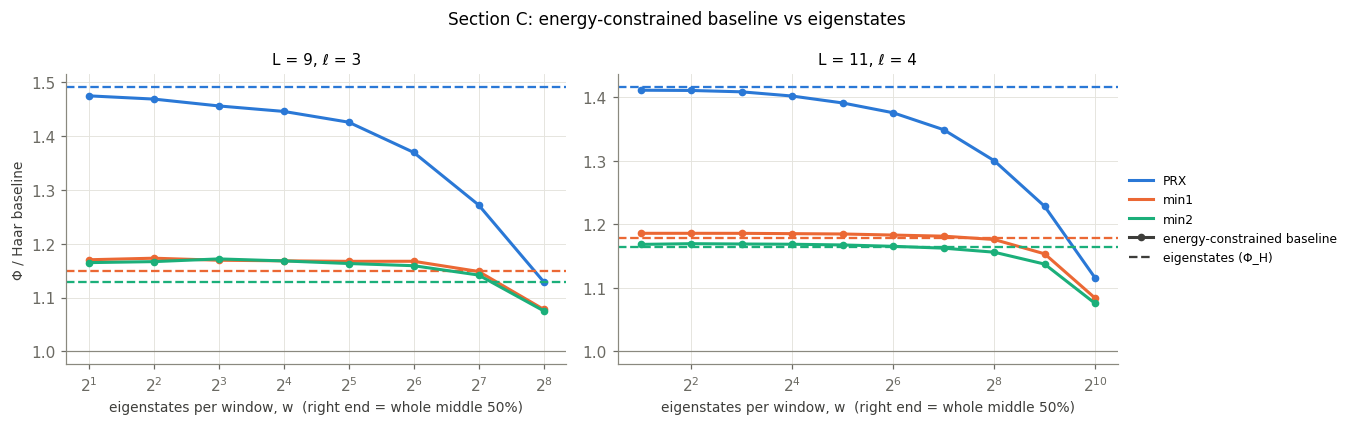

In [5]:
t0 = time.time()
SCAN, rows = {}, []
for (L, l) in SIZES:
    geo = GEO[L]
    ws = [2 ** j for j in range(1, int(np.log2(geo.k_mid)) + 1)]
    for name in NAMES:
        s = SYS[(L, name)]
        sigma_E = s['E'].std()
        for w in ws:
            ec = ec_scan(s['Vm'], geo, s['real'], w)
            nwin = geo.k_mid // w
            dE = np.mean([s['Em'][(i + 1) * w - 1] - s['Em'][i * w] for i in range(nwin)])
            SCAN[(L, name, w)] = ec
            rows.append({'L': L, 'H': name, 'w': w, 'dE / sigma_E': dE / sigma_E, 'EC': ec,
                         'EC / Haar': ec / s['haar'], 'Phi_H / EC': s['phi_H'] / ec,
                         'fraction explained': (ec - s['haar']) / (s['phi_H'] - s['haar'])})
    print(f'L = {L}: window scan done ({time.time() - t0:.0f} s)')
df_scan = pd.DataFrame(rows)
display(df_scan.pivot_table(index=['L', 'w'], columns='H', values=['Phi_H / EC', 'fraction explained']).round(4))
display(df_scan.pivot_table(index=['L', 'w'], columns='H', values='dE / sigma_E').round(4))

for (L, l) in SIZES:
    for name in NAMES:
        s = SYS[(L, name)]
        r2 = s['phi_H'] / SCAN[(L, name, 2)]
        print(f"FINDING  L = {L:2d} {name:5s}: Phi_H / EC = {s['phi_H'] / s['ec_mid']:.4f} (middle 50%) -> "
              f"{s['phi_H'] / SCAN[(L, name, W_REF)]:.4f} (w = {W_REF}) -> {r2:.4f} (w = 2)")

fig, axes = plt.subplots(1, len(SIZES), figsize=(5.0 * len(SIZES) + 2.4, 3.9), squeeze=False)
for ax, (L, l) in zip(axes[0], SIZES):
    for name in NAMES:
        s = SYS[(L, name)]
        d = df_scan[(df_scan.L == L) & (df_scan.H == name)]
        ax.plot(d['w'], d['EC / Haar'], color=COL[name], marker='o', ms=4)
        ax.axhline(s['phi_H'] / s['haar'], color=COL[name], ls='--', lw=1.5)
    ax.axhline(1, color='#8a897f', lw=0.8)
    ax.set_xscale('log', base=2)
    ax.set_xlabel('eigenstates per window, w  (right end = whole middle 50%)')
    ax.set_title(f'L = {L}, ℓ = {l}')
axes[0, 0].set_ylabel('Φ / Haar baseline')
handles = [Line2D([], [], color=COL[n], lw=2, label=n) for n in NAMES] + \
          [Line2D([], [], color='#3d3d3a', lw=2, marker='o', ms=4, label='energy-constrained baseline'),
           Line2D([], [], color='#3d3d3a', lw=1.5, ls='--', label='eigenstates (Φ_H)')]
axes[0, -1].legend(handles=handles, fontsize=8, loc='center left', bbox_to_anchor=(1.0, 0.5))
fig.suptitle('Section C: energy-constrained baseline vs eigenstates', fontsize=11)
fig.tight_layout(); plt.show()

## Section D: Where the improvement from PRX to the optimised Hamiltonians comes from

Write Φ_H as a product of three factors:

Φ_H = Φ_Haar × (Φ_EC / Φ_Haar) × (Φ_H / Φ_EC)

- **Φ_Haar: symmetry class.** Real (GOE) states have a larger baseline than complex (GUE) states, so breaking time reversal lowers it.
- **Φ_EC / Φ_Haar: energy shell.** How strongly energy conservation constrains local states.
- **Φ_H / Φ_EC: residual.** How the eigenstates compare with structureless states of the same energy.

Taking logs, ln(Φ_PRX / Φ_min) splits into three additive shares, one per factor. The shares below are computed at the reference window w = W_REF.

**This split depends on the reference.** Here PRX's baseline uses real mixing, because PRX is time-reversal symmetric, while the optima use complex mixing. So any extra cost that time reversal carries *under energy conservation* is counted in the "energy shell" share, and only the random-matrix part is counted as "symmetry class". Section F measures every Hamiltonian with complex mixing instead, and the attribution changes substantially.

In [6]:
rows = []
for (L, l) in SIZES:
    P = SYS[(L, 'PRX')]
    fP = (P['haar'], SCAN[(L, 'PRX', W_REF)] / P['haar'], P['phi_H'] / SCAN[(L, 'PRX', W_REF)])
    for name in ('min1', 'min2'):
        s = SYS[(L, name)]
        fM = (s['haar'], SCAN[(L, name, W_REF)] / s['haar'], s['phi_H'] / SCAN[(L, name, W_REF)])
        parts = [np.log(a / b) for a, b in zip(fP, fM)]
        tot = np.log(P['phi_H'] / s['phi_H'])
        check(f'D L = {L} {name}: decomposition adds up', np.isclose(sum(parts), tot, rtol=1e-12))
        rows.append({'L': L, 'improvement': f'PRX -> {name}', 'Phi ratio PRX/min': P['phi_H'] / s['phi_H'],
                     'share: symmetry class (GOE -> GUE)': parts[0] / tot,
                     'share: energy shell (EC/Haar)': parts[1] / tot,
                     'share: residual (Phi_H/EC)': parts[2] / tot,
                     'EC/Haar PRX -> min': f'{fP[1]:.3f} -> {fM[1]:.3f}',
                     'Phi_H/EC PRX -> min': f'{fP[2]:.4f} -> {fM[2]:.4f}'})
display(pd.DataFrame(rows).round(3))

[PASS] D L = 9 min1: decomposition adds up
[PASS] D L = 9 min2: decomposition adds up
[PASS] D L = 11 min1: decomposition adds up
[PASS] D L = 11 min2: decomposition adds up


,L,improvement,Phi ratio PRX/min,share: symmetry class (GOE -> GUE),share: energy shell (EC/Haar),share: residual (Phi_H/EC),EC/Haar PRX -> min,Phi_H/EC PRX -> min
0,9,PRX -> min1,1.372,0.175,0.694,0.131,1.456 -> 1.169,1.0243 -> 0.9828
1,9,PRX -> min2,1.396,0.166,0.652,0.183,1.456 -> 1.172,1.0243 -> 0.9638
2,11,PRX -> min1,1.238,0.138,0.806,0.056,1.408 -> 1.186,1.0055 -> 0.9936
3,11,PRX -> min2,1.253,0.130,0.827,0.042,1.408 -> 1.169,1.0055 -> 0.9960


## Section E: Is the residual below 1 real? (L = 9)

At L = 9 the optimised Hamiltonians sit *below* their own energy-constrained baseline, with Φ_H / Φ_EC ≈ 0.96–0.98. The optimiser minimised exactly this statistic on exactly these eigenstates, so part of that could be a selection effect: the optimiser picking parameters where the eigenstate fluctuations happen to be small. Two tests:

1. **Perturbation test.** Add random perturbations of relative size δ to the parameters. Small perturbations barely change the energy-shell structure, but once they exceed about one level spacing they reshuffle the eigenstate fluctuations. If the deficit is a selection effect, Φ_H / Φ_EC should rise towards the value typical of unoptimised Hamiltonians (PRX gives about 1.02) while Φ_EC stays flat.
   - min 1 and min 2: each component of x6 gets δ × mean|x6| × N(0, 1).
   - PRX: g and h each get a relative change δ × N(0, 1).
2. **Statistics the optimiser did not use.** Compute Φ_H / Φ_EC at the optimum for block sizes ℓ = 2 and 4, and for next-nearest pairs (n, n+2), not only adjacent pairs. These reuse the same eigenvectors, so they are not fully independent of the optimised statistic.

The finite-size trend from Section C, comparing L = 9 with L = 11, is a third piece of evidence.

,H,delta,Phi_H,EC (w=8),Phi_H / EC,s.e.
0,PRX,0.00,0.09814,0.09581,1.02433,0.00000
1,PRX,0.01,0.09817,0.09574,1.02541,0.00198
2,PRX,0.03,0.09770,0.09571,1.02082,0.00261
3,PRX,0.10,0.09936,0.09749,1.01950,0.00597
4,min1,0.00,0.07154,0.07280,0.98281,0.00000
5,min1,0.01,0.07190,0.07280,0.98762,0.00061
6,min1,0.03,0.07244,0.07290,0.99359,0.00107
7,min1,0.10,0.07342,0.07313,1.00392,0.00191
8,min2,0.00,0.07031,0.07295,0.96384,0.00000
9,min2,0.01,0.07049,0.07295,0.96631,0.00038


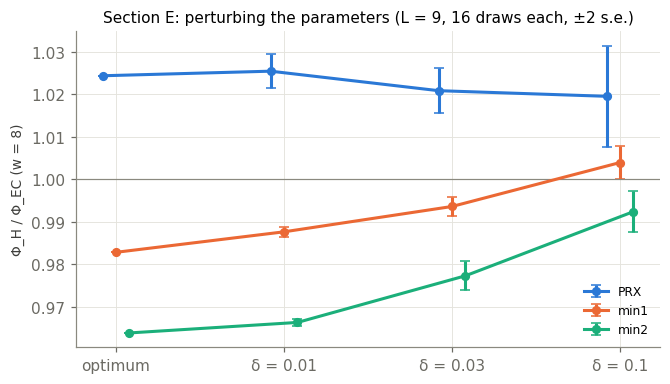

,H,l,EC (w=8),adjacent Phi_H / EC,next-nearest Phi_H / EC,used by optimiser?
0,PRX,2,0.0592,1.0390,1.0472,no
1,PRX,3,0.0958,1.0243,1.0322,yes (adjacent only)
2,PRX,4,0.1610,1.0154,1.0198,no
3,min1,2,0.0390,0.9805,0.9976,no
4,min1,3,0.0728,0.9828,0.9935,yes (adjacent only)
5,min1,4,0.1375,0.9896,0.9963,no
6,min2,2,0.0392,0.9489,0.9612,no
7,min2,3,0.0729,0.9638,0.9733,yes (adjacent only)
8,min2,4,0.1373,0.9786,0.9838,no


FINDING  min1: Phi_H/EC = 0.9828 at the optimum -> 1.0039 at delta = 0.1;  at L = 11 the optimum gives 0.9936
FINDING  min2: Phi_H/EC = 0.9638 at the optimum -> 0.9924 at delta = 0.1;  at L = 11 the optimum gives 0.9960
Section E time: 41.9 s


In [7]:
t0 = time.time()
geo9 = GEO[9]
ops9 = build_ops(9)
DELTAS = [0.01, 0.03, 0.10]
N_PERT = 6 if QUICK else 16
rows, pert = [], {}
for name in NAMES:
    kind, p0 = PARAMS[9][name]
    s = SYS[(9, name)]
    pert[(name, 0.0)] = np.array([s['phi_H'] / SCAN[(9, name, W_REF)]])
    rows.append({'H': name, 'delta': 0.0, 'Phi_H': s['phi_H'], 'EC (w=8)': SCAN[(9, name, W_REF)],
                 'Phi_H / EC': pert[(name, 0.0)][0], 's.e.': 0.0})
    for delta in DELTAS:
        r = []
        for _ in range(N_PERT):
            if kind == 'gh':
                p = np.array(p0) * (1 + delta * rng.standard_normal(2))
            else:
                p = np.array(p0) + delta * np.abs(p0).mean() * rng.standard_normal(6)
            H = hamiltonian(ops9, kind, p)
            H = H.real if s['real'] else H
            Vm = eigh(H, subset_by_index=[geo9.lo, geo9.hi])[1]
            r.append((pair_phi(Vm, geo9).mean(), ec_scan(Vm, geo9, s['real'], W_REF)))
        r = np.array(r)
        pert[(name, delta)] = r[:, 0] / r[:, 1]
        rows.append({'H': name, 'delta': delta, 'Phi_H': r[:, 0].mean(), 'EC (w=8)': r[:, 1].mean(),
                     'Phi_H / EC': pert[(name, delta)].mean(),
                     's.e.': pert[(name, delta)].std(ddof=1) / np.sqrt(N_PERT)})
del ops9; gc.collect()
display(pd.DataFrame(rows).round(5))

fig, ax = plt.subplots(figsize=(6.2, 3.6))
xs = [0.0] + DELTAS
xpos = np.arange(len(xs))
for j, name in enumerate(NAMES):
    m = [pert[(name, d)].mean() for d in xs]
    e = [0 if d == 0 else 2 * pert[(name, d)].std(ddof=1) / np.sqrt(N_PERT) for d in xs]
    ax.errorbar(xpos + (j - 1) * 0.08, m, yerr=e, color=COL[name], marker='o', ms=5, lw=2, capsize=3, label=name)
ax.axhline(1, color='#8a897f', lw=0.8)
ax.set_xticks(xpos, ['optimum'] + [f'δ = {d:g}' for d in DELTAS])
ax.set_ylabel(f'Φ_H / Φ_EC (w = {W_REF})')
ax.set_title(f'Section E: perturbing the parameters (L = 9, {N_PERT} draws each, ±2 s.e.)')
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

rows = []
for name in NAMES:
    s = SYS[(9, name)]
    for lb in (2, 3, 4):
        g = Geometry(9, lb)
        ec = ec_scan(s['Vm'], g, s['real'], W_REF)
        adj = pair_phi(s['Vm'], g).mean()
        nnn = np.mean([pair_phi(s['Vm'][:, st::2], g).mean() for st in (0, 1)])
        rows.append({'H': name, 'l': lb, 'EC (w=8)': ec, 'adjacent Phi_H / EC': adj / ec,
                     'next-nearest Phi_H / EC': nnn / ec,
                     'used by optimiser?': 'yes (adjacent only)' if lb == 3 else 'no'})
display(pd.DataFrame(rows).round(4))

for name in ('min1', 'min2'):
    lo_d, hi_d = pert[(name, 0.0)][0], pert[(name, DELTAS[-1])].mean()
    msg = f"FINDING  {name}: Phi_H/EC = {lo_d:.4f} at the optimum -> {hi_d:.4f} at delta = {DELTAS[-1]}"
    if (11, name) in SYS:
        msg += f";  at L = 11 the optimum gives {SYS[(11, name)]['phi_H'] / SCAN[(11, name, W_REF)]:.4f}"
    print(msg)
print(f'Section E time: {time.time() - t0:.1f} s')

## Section F: Time-reversal symmetry under energy conservation

**Without energy conservation.** For structureless random states, preserving time reversal (real instead of complex states) raises Φ only by the counting factor (m+2)(D+1)/((m+1)(D+2)) ≈ 1 + 1/(m+1) (PDF eq. 43). That is 5.7% at ℓ = 3 and 3.0% at ℓ = 4, and it vanishes as the block grows.

**With energy conservation.** Take a real (time-reversal-symmetric) H and mix the eigenstates inside each narrow window in two ways:
- **Real mixing** (orthogonal rotation) respects time reversal. Its baseline is the one used in Sections B–E.
- **Complex mixing** (unitary rotation) breaks it, while keeping the same energy support.

The ratio of the two baselines is the cost of time reversal once energy is conserved. It predicts how far a weak time-reversal-breaking perturbation could lower Φ: one strong enough to mix neighbouring levels, but too weak to change the energy shell.

A mechanism that fits PRX: Y_j = (i/2g)[H, Z_j], so ⟨n|Y_j|m⟩ = (i/2g)(E_m − E_n)⟨n|Z_j|m⟩. Matrix elements of this time-reversal-odd operator between eigenstates at nearly the same energy are therefore tiny. A real eigenstate has to put its fluctuations into the time-reversal-even directions, and breaking time reversal removes that squeeze.

The section has three parts:
- **F1.** The real- and complex-mixing baselines for PRX at every window size, with the cost compared against the counting factor.
- **F2.** The PRX → optimum improvement re-split using complex mixing for every Hamiltonian.
- **F3.** A scan of the time-reversal-breaking angle at fixed coupling strengths, for min 1 and min 2.

FINDING  L =  9 PRX: cost of time reversal = real / complex mixing = 1.096 (middle 50%), 1.277 (w = 8), 1.194 (w = 2); counting factor alone 1.057


FINDING  L = 11 PRX: cost of time reversal = real / complex mixing = 1.051 (middle 50%), 1.183 (w = 8), 1.132 (w = 2); counting factor alone 1.030

F1a. PRX: real vs complex mixing at each window size


,L,w,real mixing / Haar(GUE),complex mixing / Haar(GUE),TRS cost: real / complex mixing,counting factor: Haar GOE / GUE
0,9,2,1.5588,1.3050,1.1945,1.0568
1,9,4,1.5524,1.2441,1.2478,1.0568
2,9,8,1.5389,1.2051,1.2770,1.0568
3,9,16,1.5281,1.1913,1.2828,1.0568
4,9,32,1.5070,1.1885,1.2679,1.0568
5,9,64,1.4477,1.1798,1.2271,1.0568
6,9,128,1.3444,1.1576,1.1614,1.0568
7,9,256,1.1938,1.0887,1.0965,1.0568
8,11,2,1.4531,1.2841,1.1316,1.0298
9,11,4,1.4527,1.2491,1.1629,1.0298


F1b. Every Hamiltonian measured against the complex-mixing baseline


,L,H,Phi_H / Haar(GUE),"complex-mixing EC / Haar(GUE), w = 8","Phi_H / complex-mixing EC, w = 8"
0,9,PRX,1.5764,1.2051,1.3080
1,9,min1,1.1492,1.1693,0.9828
2,9,min2,1.1294,1.1718,0.9638
3,11,PRX,1.4585,1.2264,1.1892
4,11,min1,1.1780,1.1857,0.9936
5,11,min2,1.1642,1.1689,0.9960


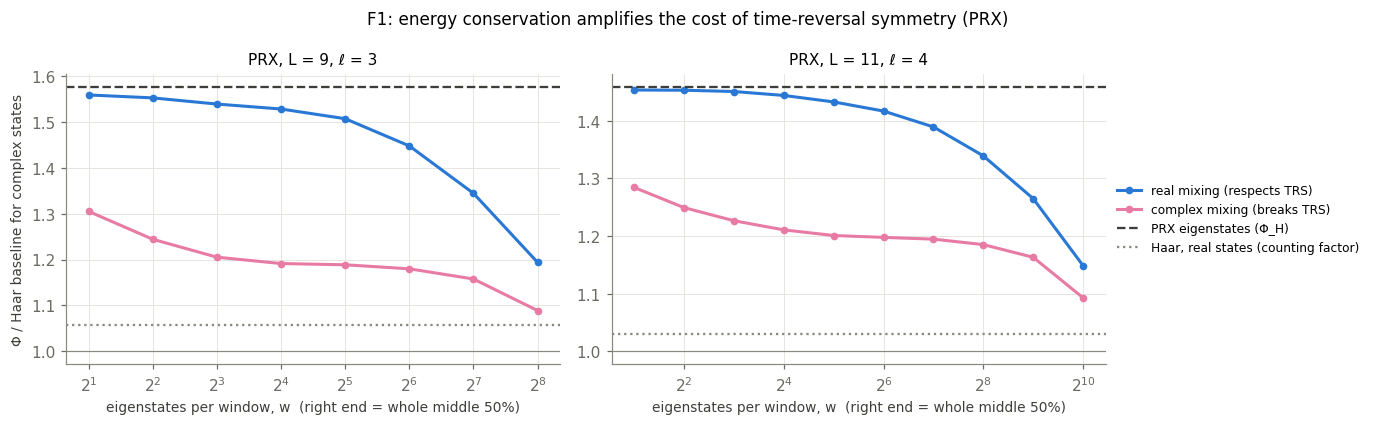

[PASS] F2 L = 9 min1: complex-reference decomposition adds up
[PASS] F2 L = 9 min2: complex-reference decomposition adds up
[PASS] F2 L = 11 min1: complex-reference decomposition adds up
[PASS] F2 L = 11 min2: complex-reference decomposition adds up
F2. Shares of ln(Phi_PRX / Phi_min) with complex mixing as the reference (w = 8)


,L,improvement,Phi ratio PRX/min,share: PRX's TRS cost under energy conservation,share: complex-mixing shell factor,share: residual (min below its baseline)
0,9,PRX -> min1,1.372,0.850,0.095,0.055
1,9,PRX -> min2,1.396,0.805,0.084,0.110
2,11,PRX -> min1,1.238,0.812,0.158,0.030
3,11,PRX -> min2,1.253,0.769,0.213,0.018


Section F1-F2 time: 14.8 s


In [8]:
t0 = time.time()
SCAN_U, rows, rows_shell = {}, [], []
for (L, l) in SIZES:
    geo = GEO[L]
    ws = [2 ** j for j in range(1, int(np.log2(geo.k_mid)) + 1)]
    hz_goe, hz_gue = mu_haar_orth(True, geo.mb, geo.n_env), mu_haar_orth(False, geo.mb, geo.n_env)
    for name in NAMES:
        s = SYS[(L, name)]
        for w in ws:   # complex-mixing baseline; for complex H it is the Section C baseline
            SCAN_U[(L, name, w)] = ec_scan(s['Vm'], geo, False, w) if s['real'] else SCAN[(L, name, w)]
        rows_shell.append({'L': L, 'H': name, 'Phi_H / Haar(GUE)': s['phi_H'] / hz_gue,
                           f'complex-mixing EC / Haar(GUE), w = {W_REF}': SCAN_U[(L, name, W_REF)] / hz_gue,
                           f'Phi_H / complex-mixing EC, w = {W_REF}': s['phi_H'] / SCAN_U[(L, name, W_REF)]})
    for w in ws:
        rows.append({'L': L, 'w': w, 'real mixing / Haar(GUE)': SCAN[(L, 'PRX', w)] / hz_gue,
                     'complex mixing / Haar(GUE)': SCAN_U[(L, 'PRX', w)] / hz_gue,
                     'TRS cost: real / complex mixing': SCAN[(L, 'PRX', w)] / SCAN_U[(L, 'PRX', w)],
                     'counting factor: Haar GOE / GUE': hz_goe / hz_gue})
    P = SYS[(L, 'PRX')]
    print(f"FINDING  L = {L:2d} PRX: cost of time reversal = real / complex mixing = "
          f"{SCAN[(L, 'PRX', geo.k_mid)] / SCAN_U[(L, 'PRX', geo.k_mid)]:.3f} (middle 50%), "
          f"{SCAN[(L, 'PRX', W_REF)] / SCAN_U[(L, 'PRX', W_REF)]:.3f} (w = {W_REF}), "
          f"{SCAN[(L, 'PRX', 2)] / SCAN_U[(L, 'PRX', 2)]:.3f} (w = 2); counting factor alone {hz_goe / hz_gue:.3f}")
df_trs = pd.DataFrame(rows)
print('\nF1a. PRX: real vs complex mixing at each window size')
display(df_trs.round(4))
print('F1b. Every Hamiltonian measured against the complex-mixing baseline')
display(pd.DataFrame(rows_shell).round(4))

fig, axes = plt.subplots(1, len(SIZES), figsize=(5.0 * len(SIZES) + 2.6, 3.9), squeeze=False)
for ax, (L, l) in zip(axes[0], SIZES):
    d = df_trs[df_trs.L == L]
    hz_gue = mu_haar_orth(False, GEO[L].mb, GEO[L].n_env)
    ax.plot(d['w'], d['real mixing / Haar(GUE)'], color=C_PRX_REAL, marker='o', ms=4)
    ax.plot(d['w'], d['complex mixing / Haar(GUE)'], color=C_PRX_CPLX, marker='o', ms=4)
    ax.axhline(SYS[(L, 'PRX')]['phi_H'] / hz_gue, color='#3d3d3a', ls='--', lw=1.5)
    ax.axhline(d['counting factor: Haar GOE / GUE'].iloc[0], color='#8a897f', ls=':', lw=1.5)
    ax.axhline(1, color='#8a897f', lw=0.8)
    ax.set_xscale('log', base=2)
    ax.set_xlabel('eigenstates per window, w  (right end = whole middle 50%)')
    ax.set_title(f'PRX, L = {L}, ℓ = {l}')
axes[0, 0].set_ylabel('Φ / Haar baseline for complex states')
handles = [Line2D([], [], color=C_PRX_REAL, lw=2, marker='o', ms=4, label='real mixing (respects TRS)'),
           Line2D([], [], color=C_PRX_CPLX, lw=2, marker='o', ms=4, label='complex mixing (breaks TRS)'),
           Line2D([], [], color='#3d3d3a', lw=1.5, ls='--', label='PRX eigenstates (Φ_H)'),
           Line2D([], [], color='#8a897f', lw=1.5, ls=':', label='Haar, real states (counting factor)')]
axes[0, -1].legend(handles=handles, fontsize=8, loc='center left', bbox_to_anchor=(1.0, 0.5))
fig.suptitle('F1: energy conservation amplifies the cost of time-reversal symmetry (PRX)', fontsize=11)
fig.tight_layout(); plt.show()

# ---- F2: the PRX -> optimum improvement, with complex mixing as the reference for every H ----
rows = []
for (L, l) in SIZES:
    P = SYS[(L, 'PRX')]
    ecP = SCAN_U[(L, 'PRX', W_REF)]
    for name in ('min1', 'min2'):
        s = SYS[(L, name)]
        ecM = SCAN_U[(L, name, W_REF)]
        parts = [np.log(P['phi_H'] / ecP), np.log(ecP / ecM), np.log(ecM / s['phi_H'])]
        tot = np.log(P['phi_H'] / s['phi_H'])
        check(f'F2 L = {L} {name}: complex-reference decomposition adds up', np.isclose(sum(parts), tot, rtol=1e-12))
        rows.append({'L': L, 'improvement': f'PRX -> {name}', 'Phi ratio PRX/min': P['phi_H'] / s['phi_H'],
                     "share: PRX's TRS cost under energy conservation": parts[0] / tot,
                     'share: complex-mixing shell factor': parts[1] / tot,
                     'share: residual (min below its baseline)': parts[2] / tot})
print(f'F2. Shares of ln(Phi_PRX / Phi_min) with complex mixing as the reference (w = {W_REF})')
display(pd.DataFrame(rows).round(3))
print(f'Section F1-F2 time: {time.time() - t0:.1f} s')

### F3: Scanning the time-reversal-breaking angle at fixed coupling strengths

A uniform spin rotation about z leaves Φ and the spectrum unchanged. It rotates the vector (c_XZ+ZX, c_YZ+ZY) by an angle φ and the vector (c_XX − c_YY, 2c_XY+YX) by 2φ, and leaves J, c_XX + c_YY, the Z field and the edge fields alone. In the standard frame (c_YZ+ZY = 0, c_XZ+ZX > 0), H is real exactly when c_XY+YX = 0.

Write (c_XX − c_YY, 2c_XY+YX) = r(cos θ, sin θ). Then θ is a pure time-reversal-breaking angle:
- θ = 0° and θ = 180° are real Hamiltonians, with time reversal preserved.
- Other values of θ are complex. The angles θ and −θ give complex-conjugate Hamiltonians with the same Φ, so 0°–180° covers every case.
- Each optimum sits at θ_opt = |atan2(2c_XY+YX, c_XX − c_YY)|.

The scan keeps every other coupling fixed and varies θ. For each angle it records Φ_H, the complex-mixing baseline at w = W_REF, and ⟨r⟩.

[PASS] F3 L = 9 min1: standard-frame parameters reproduce Phi_H   (0.07154433)


[PASS] F3 L = 9 min1: the scan at theta_opt reproduces the optimum   (theta_opt = 104.3 deg)


[PASS] F3 L = 9 min2: standard-frame parameters reproduce Phi_H   (0.07031195)


[PASS] F3 L = 9 min2: the scan at theta_opt reproduces the optimum   (theta_opt = 137.7 deg)


L = 9: angle scan done (10 s)


[PASS] F3 L = 11 min1: standard-frame parameters reproduce Phi_H   (0.03677807)


... (2 outputs left out)

[PASS] F3 L = 11 min2: the scan at theta_opt reproduces the optimum   (theta_opt = 154.7 deg)


L = 11: angle scan done (251 s)


,L,H,theta (deg),real H,optimum,Phi_H,Phi_H / Haar(GUE),complex-mixing EC / Haar(GUE),Phi_H / complex-mixing EC,Phi_H / real-mixing EC,<r>
0,9,min1,0.0000,True,False,0.2265,3.6387,1.4867,2.4474,1.7035,0.5004
1,9,min1,15.0000,False,False,0.1744,2.8017,1.4382,1.9481,NaN,0.5318
2,9,min1,30.0000,False,False,0.1217,1.9556,1.3396,1.4599,NaN,0.5654
3,9,min1,45.0000,False,False,0.0930,1.4932,1.2767,1.1695,NaN,0.5732
4,9,min1,60.0000,False,False,0.0809,1.2999,1.2307,1.0563,NaN,0.5612
5,9,min1,75.0000,False,False,0.0756,1.2142,1.2010,1.0110,NaN,0.5901
6,9,min1,90.0000,False,False,0.0736,1.1817,1.1805,1.0010,NaN,0.5756
7,9,min1,104.3427,False,True,0.0715,1.1492,1.1693,0.9828,NaN,0.5683
8,9,min1,105.0000,False,False,0.0716,1.1499,1.1690,0.9837,NaN,0.5697
9,9,min1,120.0000,False,False,0.0719,1.1557,1.1623,0.9943,NaN,0.5885


FINDING  L =  9 min1: restoring time reversal at fixed couplings (theta = 180 deg) raises Phi by 8.2%; complex-mixing baseline 1.169 -> 1.166; Phi_H / complex-mixing EC 0.983 -> 1.067
FINDING  L =  9 min2: restoring time reversal at fixed couplings (theta = 180 deg) raises Phi by 12.9%; complex-mixing baseline 1.172 -> 1.173; Phi_H / complex-mixing EC 0.964 -> 1.087
FINDING  L = 11 min1: restoring time reversal at fixed couplings (theta = 180 deg) raises Phi by 5.0%; complex-mixing baseline 1.186 -> 1.184; Phi_H / complex-mixing EC 0.994 -> 1.045
FINDING  L = 11 min2: restoring time reversal at fixed couplings (theta = 180 deg) raises Phi by 9.1%; complex-mixing baseline 1.169 -> 1.180; Phi_H / complex-mixing EC 0.996 -> 1.076


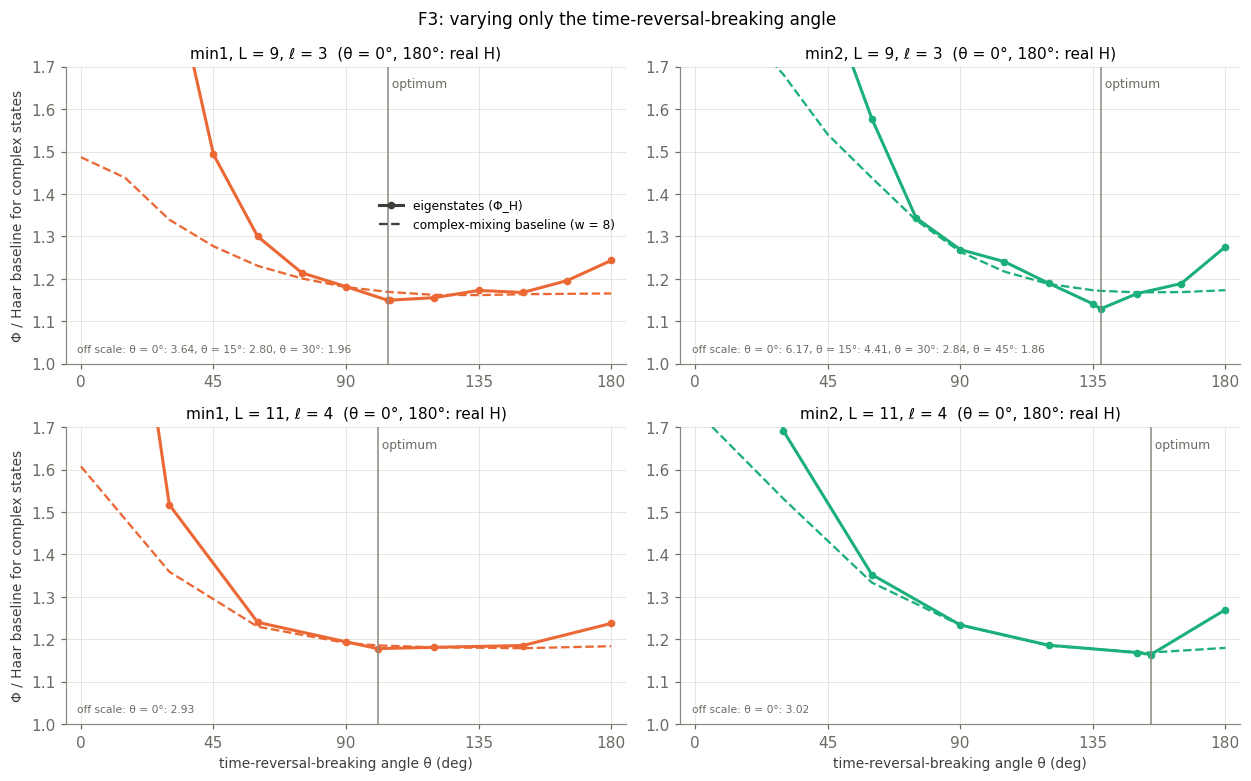

Section F3 time: 251.4 s


In [9]:
t0 = time.time()


def to_standard(x):
    # Canonical-frame x6 -> standard frame (c_YZ+ZY = 0, c_XZ+ZX > 0) by a uniform z rotation.
    J, a, b, t, f, g = x
    phi = -np.arctan2(g, f)
    rot = lambda ang: np.array([[np.cos(ang), -np.sin(ang)], [np.sin(ang), np.cos(ang)]])
    f2, _ = rot(phi) @ [f, g]
    d2, tt2 = rot(2 * phi) @ [a - b, 2 * t]
    return [J, (a + b + d2) / 2, (a + b - d2) / 2, tt2 / 2, f2, 0.0]


def with_theta(xs, theta):
    # Same couplings, time-reversal-breaking angle set to theta (standard frame).
    J, a, b, t, f, _ = xs
    r = np.hypot(a - b, 2 * t)
    return [J, (a + b + r * np.cos(theta)) / 2, (a + b - r * np.cos(theta)) / 2, r * np.sin(theta) / 2, f, 0.0]


def theta_of(xs):
    return abs(np.arctan2(2 * xs[3], xs[1] - xs[2]))


N_THETA = {9: 13, 11: 7}
ANGLE, rows = {}, []
for (L, l) in SIZES:
    geo = GEO[L]
    hz_gue = mu_haar_orth(False, geo.mb, geo.n_env)
    ops = build_ops(L)
    for name in ('min1', 'min2'):
        xs = to_standard(PARAMS[L][name][1])
        th0 = theta_of(xs)
        H = hamiltonian(ops, 'x6', xs)
        phi_std = pair_phi(eigh(H, subset_by_index=[geo.lo, geo.hi])[1], geo).mean()
        check(f'F3 L = {L} {name}: standard-frame parameters reproduce Phi_H',
              np.isclose(phi_std, SYS[(L, name)]['phi_H'], rtol=1e-8), f'{phi_std:.8f}')
        grid = sorted(set(np.round(np.append(np.linspace(0, np.pi, N_THETA.get(L, 7)), th0), 12)))
        for th in grid:
            H = hamiltonian(ops, 'x6', with_theta(xs, th))
            real = bool(np.allclose(H.imag, 0))
            H = H.real if real else H
            E, V = eigh(H, subset_by_index=[geo.lo, geo.hi])
            phi = pair_phi(V, geo).mean()
            ecu = ec_scan(V, geo, False, W_REF)
            ecr = ec_scan(V, geo, True, W_REF) if real else np.nan
            opt = bool(np.isclose(th, th0))
            if opt:
                check(f'F3 L = {L} {name}: the scan at theta_opt reproduces the optimum',
                      np.isclose(phi, SYS[(L, name)]['phi_H'], rtol=1e-8), f'theta_opt = {np.degrees(th0):.1f} deg')
            rows.append({'L': L, 'H': name, 'theta (deg)': np.degrees(th), 'real H': real, 'optimum': opt,
                         'Phi_H': phi, 'Phi_H / Haar(GUE)': phi / hz_gue,
                         'complex-mixing EC / Haar(GUE)': ecu / hz_gue, 'Phi_H / complex-mixing EC': phi / ecu,
                         'Phi_H / real-mixing EC': phi / ecr, '<r>': r_stat(E)})
    del ops; gc.collect()
    print(f'L = {L}: angle scan done ({time.time() - t0:.0f} s)')
df_ang = pd.DataFrame(rows)
display(df_ang.round(4))

for (L, l) in SIZES:
    for name in ('min1', 'min2'):
        d = df_ang[(df_ang.L == L) & (df_ang.H == name)]
        o, r180 = d[d.optimum].iloc[0], d[np.isclose(d['theta (deg)'], 180)].iloc[0]
        print(f"FINDING  L = {L:2d} {name}: restoring time reversal at fixed couplings (theta = 180 deg) raises Phi by "
              f"{100 * (r180['Phi_H'] / o['Phi_H'] - 1):.1f}%; complex-mixing baseline "
              f"{o['complex-mixing EC / Haar(GUE)']:.3f} -> {r180['complex-mixing EC / Haar(GUE)']:.3f}; "
              f"Phi_H / complex-mixing EC {o['Phi_H / complex-mixing EC']:.3f} -> {r180['Phi_H / complex-mixing EC']:.3f}")

fig, axes = plt.subplots(len(SIZES), 2, figsize=(11.5, 3.6 * len(SIZES)), squeeze=False)
YTOP = 1.7
for i, (L, l) in enumerate(SIZES):
    for j, name in enumerate(('min1', 'min2')):
        ax = axes[i, j]
        d = df_ang[(df_ang.L == L) & (df_ang.H == name)]
        ax.plot(d['theta (deg)'], d['Phi_H / Haar(GUE)'], color=COL[name], marker='o', ms=4)
        ax.plot(d['theta (deg)'], d['complex-mixing EC / Haar(GUE)'], color=COL[name], ls='--', lw=1.5)
        th0 = d[d.optimum]['theta (deg)'].iloc[0]
        ax.axvline(th0, color='#8a897f', lw=1)
        ax.text(th0, YTOP * 0.985, ' optimum', color='#6b6a63', fontsize=8, va='top')
        off = d[d['Phi_H / Haar(GUE)'] > YTOP]
        if len(off):
            ax.text(0.02, 0.04, 'off scale: ' + ', '.join(f"θ = {t:.0f}°: {v:.2f}" for t, v in
                    zip(off['theta (deg)'], off['Phi_H / Haar(GUE)'])), transform=ax.transAxes, fontsize=7, color='#6b6a63')
        ax.set_ylim(1.0, YTOP); ax.set_xlim(-5, 185); ax.set_xticks([0, 45, 90, 135, 180])
        ax.set_title(f'{name}, L = {L}, ℓ = {l}  (θ = 0°, 180°: real H)')
        if i == len(SIZES) - 1: ax.set_xlabel('time-reversal-breaking angle θ (deg)')
        if j == 0: ax.set_ylabel('Φ / Haar baseline for complex states')
handles = [Line2D([], [], color='#3d3d3a', lw=2, marker='o', ms=4, label='eigenstates (Φ_H)'),
           Line2D([], [], color='#3d3d3a', lw=1.5, ls='--', label=f'complex-mixing baseline (w = {W_REF})')]
axes[0, 0].legend(handles=handles, fontsize=8, loc='center right')
fig.suptitle('F3: varying only the time-reversal-breaking angle', fontsize=11)
fig.tight_layout(); plt.show()
print(f'Section F3 time: {time.time() - t0:.1f} s')

## Results of the reference run

Settings: `QUICK = False`, seed 20261124, run time 7.6 minutes, 33/33 checks passed. "Baseline" means the energy-constrained baseline Φ_EC unless it says Haar. "Real mixing" and "complex mixing" mean orthogonal and unitary rotations within each energy window (Section F).

### Summary

> For structureless states, time-reversal symmetry changes Φ only through a random-matrix counting factor of about 1 + 1/(m+1). That factor is small for our block sizes (5.7% at ℓ = 3, 3.0% at ℓ = 4) and vanishes as the block grows. Energy conservation changes this. In a time-reversal-symmetric Hamiltonian, eigenstates at nearly equal energies cannot differ along time-reversal-odd directions, so preserving the symmetry can cost much more. For PRX the cost is up to 28% at L = 9 and 19% at L = 11, five to six times the counting factor. The size of the cost depends on the Hamiltonian: restoring time reversal in the optimised couplings costs only 5–13%. Whether the cost persists at larger L is still open.

### Details

**1. The middle-50% restriction on its own is a weak constraint (Section B).** It raises the baseline above Haar by 7–13%, which explains only part of each Hamiltonian's excess over Haar:

| Fraction of Φ_H's excess over Haar explained | PRX | min 1 | min 2 |
|---|---|---|---|
| L = 9 | 26% | 52% | 58% |
| L = 11 | 28% | 47% | 46% |

**2. Narrow energy windows account for essentially all of the excess (Section C).** For PRX, Φ_H / baseline falls from 1.32 (L = 9) and 1.27 (L = 11) with the middle-50% window to 1.011 and 1.004 with w = 2. That is 96.6% and 98.7% of the excess. Within narrow windows, the eigenstates of all three Hamiltonians are about as structureless as energy conservation allows.

**3. Energy conservation amplifies the cost of time reversal (Section F1).** The cost is measured for PRX as the ratio of its real-mixing to complex-mixing baseline:

| PRX | w = 2 | w = 8 | largest | whole middle 50% | counting factor (structureless) |
|---|---|---|---|---|---|
| L = 9, ℓ = 3 | 1.194 | 1.277 | 1.283 (w = 16) | 1.096 | 1.057 |
| L = 11, ℓ = 4 | 1.132 | 1.183 | 1.193 (w = 32) | 1.051 | 1.030 |

- The cost is largest for windows of tens of eigenstates and shrinks as the window widens towards the whole middle 50%, where the energy constraint is weak.
- It is smaller at L = 11 than at L = 9, but its excess over 1 is still five to six times the counting factor's.
- Measured against complex mixing, PRX sits at 1.31× its baseline (L = 9) and 1.19× (L = 11). The optimised Hamiltonians sit at 0.96–1.00×.

**4. Turning only the time-reversal-breaking angle (Section F3).** At fixed coupling strengths, restoring time reversal at θ = 180° gives the following, with min 1 / min 2 values separated by slashes:

| | Φ increase | complex-mixing baseline | Φ_H / baseline: optimum → θ = 180° |
|---|---|---|---|
| L = 9 | 8.2% / 12.9% | unchanged (within 1%) | 0.98 / 0.96 → 1.07 / 1.09 |
| L = 11 | 5.0% / 9.1% | unchanged (within 1%) | 0.99 / 1.00 → 1.05 / 1.08 |

- A small tilt away from θ = 180° drops Φ_H back onto the complex-mixing baseline (at 165°, L = 9: 1.03 / 1.02). This is the behaviour the time-reversal-cost picture predicts.
- The other real point, θ = 0°, is far worse: Φ is 3–6× Haar, and at L = 9 ⟨r⟩ falls below the GOE value. How much time reversal costs therefore depends strongly on the coupling pattern, not only on whether H is real.

**5. Where the PRX → optimum improvement comes from depends on the reference.** Both accountings use w = 8 and split ln(Φ_PRX / Φ_min) into three additive shares:

| | Section D: symmetry class / energy shell / residual | Section F2: PRX's time-reversal cost under energy conservation / complex-mixing shell / residual |
|---|---|---|
| L = 9, PRX → min 1 | 17% / 69% / 13% | 85% / 10% / 6% |
| L = 9, PRX → min 2 | 17% / 65% / 18% | 80% / 8% / 11% |
| L = 11, PRX → min 1 | 14% / 81% / 6% | 81% / 16% / 3% |
| L = 11, PRX → min 2 | 13% / 83% / 4% | 77% / 21% / 2% |

Section D measures PRX with real mixing, so the amplified time-reversal cost lands in its "energy shell" share. Section F2 measures every Hamiltonian with complex mixing, which isolates that cost. On that reading, about 77–85% of the improvement comes from removing PRX's time-reversal cost, and the part due to a genuinely smaller energy shell grows from about 9% at L = 9 to 16–21% at L = 11.

**6. The optimised Hamiltonians sit slightly below their baseline, mostly as a selection and finite-size effect (Section E).**
- At the optimum, L = 9: Φ_H / baseline is 0.983 (min 1) and 0.964 (min 2).
- Under random parameter perturbations of δ = 0.1 it rises to 1.004 and 0.992, while the baseline stays flat.
- At L = 11 it is 0.994 and 0.996.

### What this does not settle

- **The direct test on PRX.** Adding a weak time-reversal-breaking term to PRX should drop Φ towards its complex-mixing baseline (about 0.075 at L = 9, compared with 0.098). The angle scan shows this behaviour for the optimised couplings, but it hasn't been run for PRX itself.
- **Scaling.** The cost falls from L = 9 to L = 11, but ℓ changes along with L. Separating the two (for example ℓ = 3 at L = 11) and adding L = 13 would show whether the amplified cost survives.
- **What sets the cost.** For PRX, Y_j = (i/2g)[H, Z_j] illustrates why time-reversal-odd directions freeze at fixed energy. Which coupling patterns make the cost large or small, as at θ = 0° versus 180°, is not yet understood.

## Summary of checks

In [10]:
df_checks = pd.DataFrame(CHECKS, columns=['check', 'passed', 'detail'])
with pd.option_context('display.max_colwidth', 120):
    display(df_checks)
n_fail = int((~df_checks['passed']).sum())
print(f"{len(df_checks) - n_fail}/{len(df_checks)} checks passed; total run time {time.time() - T_START:.0f} s")

,check,passed,detail
0,L = 9 PRX: Phi_H matches the coupling-search value,True,0.09813847 vs 0.09813847
1,L = 9 min1: Phi_H matches the coupling-search value,True,0.07154433 vs 0.07154433
2,L = 9 min2: Phi_H matches the coupling-search value,True,0.07031195 vs 0.07031195
3,L = 11 PRX: Phi_H matches the coupling-search value,True,0.04553219 vs 0.04553219
4,L = 11 min1: Phi_H matches the coupling-search value,True,0.03677807 vs 0.03677807
5,L = 11 min2: Phi_H matches the coupling-search value,True,0.03634512 vs 0.03634512
6,A1 L = 9 orthogonal: Pi = I reproduces the Haar baseline,True,0.0657899746 vs 0.0657899746
7,A1 L = 9 unitary: Pi = I reproduces the Haar baseline,True,0.0622560969 vs 0.0622560969
8,A1 L = 11 orthogonal: Pi = I reproduces the Haar baseline,True,0.0321498445 vs 0.0321498445
9,A1 L = 11 unitary: Pi = I reproduces the Haar baseline,True,0.0312194899 vs 0.0312194899


33/33 checks passed; total run time 455 s
